# X-Wines: Factorization Machines, Content and Hybrid Models (Person D, Tasks 3 and 5)

**Question:** what do wine attributes (type, grapes, country, region, ABV) and rating context (time, vintage age)
add to user and wine identities, for wines that already have ratings and for new wines?

| Part | What | Section in merged notebook |
|---|---|---|
| Main model | Factorization machine on IDs + metadata + context: our L-BFGS FM, plus a library Bayesian FM (myFM) | 3.3 |
| Ablation | IDs → +type → +country → +grape → +region → all → +time; time vs vintage age separated | 3.3 |
| Extra features | Body, Acidity, Harmonize (food pairings), clearly labelled | 3.3 |
| Cold start | the repo's `cold_item` split (test wines never seen in training) | 3.3 |
| Results | final table with A's and C's models, feature weights, error slices | 5.1, 5.3 |
| Ranking | Top-10 precision/recall, MRR, AUC and diversity: FM vs C's MF | 5.4 |

Protocol (shared with the team; see `docs/evaluation_protocol.md`): the verified **chronological** split of the
Slim edition; fit on train, tune on validation, score test once for each validation-selected model. RMSE is
primary, MAE secondary, predictions clipped to [1, 5], seed 258. All model code is in `src/fm.py`; the
written findings are in `reports/D_findings.md`.

In [1]:
from pathlib import Path
import sys, os, time, json, subprocess, warnings
ROOT = Path.cwd()
if not (ROOT/'src/fm.py').exists(): ROOT = ROOT.parent
assert (ROOT/'src/fm.py').exists(), 'Run from repo root or notebooks/'
sys.path.insert(0, str(ROOT))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT/'.cache/matplotlib'))
os.environ['TQDM_DISABLE'] = '1'                      # myFM progress bars
# myFM imports the deprecated pkg_resources; silence that warning here and in parallel worker processes.
os.environ['PYTHONWARNINGS'] = 'ignore::UserWarning'
warnings.filterwarnings('ignore', category=UserWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.pipeline import load_prepared_splits, score_predictions
from src.experiments import (SEED, SAFE_META, metrics, baseline_predictions, cluster_bootstrap,
                             error_slices, join_metadata, FeatureProbe)
from src.fm import (FMRecommender, BayesianFM, ABLATION, ALL_STATIC, CONTEXT, EXTRA, ID_FIELDS,
                    evaluate_fm, evaluate_bayes, grid_search, best_params, interaction_spread,
                    prediction_frame, fm_score_matrix, frame_score_matrix, topk_setup, topk_metrics,
                    diversity)
from src.cf import BiasBaseline, ALSMF

REPORTS = ROOT/'reports'; FIGURES = REPORTS/'figures'; OUTPUTS = ROOT/'outputs'
for folder in (FIGURES, OUTPUTS): folder.mkdir(parents=True, exist_ok=True)
N_JOBS = min(8, os.cpu_count() or 1)
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
INK, MUTED = '#2b2b2b', '#8a8a85'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.size': 10, 'axes.edgecolor': MUTED, 'axes.grid': True,
                     'grid.color': '#e6e5df', 'grid.linewidth': 0.6, 'lines.linewidth': 2})

wines, parts = load_prepared_splits(ROOT, 'chronological')
train, validation, test = parts['train'], parts['validation'], parts['test']
# Team names: train, validation, test. fm_* are the same rows joined with wine metadata (the FM needs it).
fm_train, fm_val, fm_test = (join_metadata(f, wines) for f in (train, validation, test))
print({k: len(v) for k, v in parts.items()}, '| seed', SEED, '| parallel jobs', N_JOBS)

{'train': 120000, 'validation': 15000, 'test': 15000} | seed 258 | parallel jobs 8


## 3.3.1 The factorization machine

Each rating event is a sparse feature vector $x$: one-hot user and wine, one-hot type / elaborate / country /
region / winery, fractional multi-hot grapes ($1/k$ for a blend of $k$ grapes), standardized ABV with a missing
flag, and (optionally) the context features rating month (sin/cos), rating year and rated-vintage age with a
missing flag. A second-order FM predicts

$$\hat r(x) = w_0 + \sum_j w_j x_j + \sum_{j<l} \langle v_j, v_l \rangle x_j x_l ,$$

so besides an additive weight per feature it learns a $k$-dimensional factor $v_j$ per feature, and every pair of
active features interacts, e.g. *user × grape*, *user × country*, *type × rating year*. With only user and wine
active this is exactly matrix factorization $\mu + b_u + b_i + p_u\cdot q_i$ (C's model); with $k = 0$ it is ridge
regression on the same features (the repo's `FeatureProbe`).

**Implementation.** The plan was fastFM, but it does not build on Python 3.11 / NumPy 2 (both the PyPI release
and the GitHub source fail at the wheel-build step). We therefore use
1. **our own FM** (`src/fm.py`, `FactorizationMachine`): the pairwise term computed in $O(k \cdot \text{nnz})$ as
   $\tfrac12\sum_f[(xV)_f^2 - (x^2V^2)_f]$, objective
   $\tfrac12\sum(\hat r - r)^2 + \tfrac12\lambda_w\lVert w\rVert^2 + \tfrac12\lambda_V\lVert V\rVert^2$,
   minimized with **full-batch L-BFGS** (SciPy) using the analytic gradient (checked against finite differences in
   `tests/test_fm.py`). Each loss/gradient evaluation is a few sparse matrix products, so no per-row Python loop
   and no learning rate to tune; factors start from $N(0, 0.01^2)$, seed 258.
2. **a library FM, myFM** (`BayesianFM`): a Bayesian FM fitted by Gibbs sampling, with one hyperprior group per
   field, so it *learns* a separate regularization strength for users, wines and each metadata field.

All encoders (vocabularies, ABV median/sd over unique training wines, median vintage age) are fitted on training
rows only. An unseen user, wine or region simply has no column, so it contributes zero and the remaining features
still score the event; this is the FM's built-in fallback.

In [2]:
fm_fields = ALL_STATIC + CONTEXT        # the main model's features: IDs + all safe metadata + time + age
print('FM fields:', fm_fields)
example = FMRecommender(fm_fields).encoder.fit(fm_train)
print(f'{example.n_features:,} training features;',
      pd.Series(example.column_field).value_counts().to_dict())

FM fields: ['UserID', 'WineID', 'Type', 'Elaborate', 'Country', 'RegionID', 'WineryID', 'Grapes', 'ABV', 'Time', 'Age']
12,709 training features; {'UserID': 10357, 'WineID': 1000, 'WineryID': 787, 'RegionID': 321, 'Grapes': 187, 'Country': 31, 'Elaborate': 13, 'Type': 6, 'Time': 3, 'ABV': 2, 'Age': 2}


### Hyperparameter grid (validation)

Grid on the full feature set: $k \in \{0, 2, 4, 8, 16\}$, $\lambda_w \in \{3, 5, 10\}$ (the linear weights,
dominated by the user/wine IDs; $k = 0$ also tries 2 and 7) and $\lambda_V \in \{100, 300, 1000\}$. $k = 0$ is the
linear model. The
library FM is run with $k \in \{0, 4, 8\}$ and 300 Gibbs sweeps (the first 50 discarded).

In [3]:
fm_configs = [('fm', fm_fields, dict(n_factors=0, reg_linear=rl)) for rl in [2., 3., 5., 7., 10.]]
fm_configs += [('fm', fm_fields, dict(n_factors=k, reg_linear=rl, reg_factors=rv))
               for k in [2, 4, 8, 16] for rl in [3., 5., 10.] for rv in [100., 300., 1000.]]
start = time.perf_counter()
fm_grid = grid_search(fm_train, fm_val, fm_configs, n_jobs=N_JOBS)
fm_grid['model'] = 'fm (ours, L-BFGS)'
bayes_grid = grid_search(fm_train, fm_val, [('fm', fm_fields, dict(n_factors=k, n_iter=300, n_kept=250))
                                            for k in [0, 4, 8]], n_jobs=3, evaluator=evaluate_bayes)
print(f'Grid: {len(fm_grid) + len(bayes_grid)} fits in {time.perf_counter() - start:.0f}s')
fm_grid.to_csv(REPORTS/'D_fm_grid.csv', index=False)
bayes_grid.to_csv(REPORTS/'D_bayesian_fm_grid.csv', index=False)
fm_best = best_params(fm_grid)
fm_linear_best = best_params(fm_grid[fm_grid.n_factors == 0])
fm_best_val = fm_grid.val_rmse.min()
print('Selected FM:', fm_best, f'validation RMSE {fm_best_val:.4f}')
print('Best linear (k = 0):', fm_linear_best, f'validation RMSE {fm_grid[fm_grid.n_factors == 0].val_rmse.min():.4f}')
display(fm_grid[fm_grid.n_factors > 0].pivot_table(index=['n_factors', 'reg_linear'], columns='reg_factors',
                                                   values='val_rmse').round(4))
display(bayes_grid[['model', 'n_factors', 'sweeps', 'fit_seconds', 'train_rmse', 'val_rmse', 'val_mae']].round(4))

Grid: 44 fits in 184s
Selected FM: {'n_factors': 8, 'reg_linear': 5.0, 'reg_factors': 300.0} validation RMSE 0.4416
Best linear (k = 0): {'n_factors': 0, 'reg_linear': 5.0, 'reg_factors': 10.0} validation RMSE 0.4419


reg_factors           100.0   300.0   1000.0
n_factors reg_linear                        
2         3.0         0.4430  0.4431  0.4433
          5.0         0.4419  0.4416  0.4419
          10.0        0.4435  0.4436  0.4440
4         3.0         0.4445  0.4430  0.4433
          5.0         0.4437  0.4416  0.4419
          10.0        0.4455  0.4435  0.4440
8         3.0         0.4444  0.4430  0.4433
          5.0         0.4435  0.4416  0.4419
          10.0        0.4444  0.4435  0.4440
16        3.0         0.4444  0.4430  0.4433
          5.0         0.4435  0.4416  0.4419
          10.0        0.4444  0.4435  0.4440

,model,n_factors,sweeps,fit_seconds,train_rmse,val_rmse,val_mae
0,bayesian_fm (myFM),0,300,2.5181,0.4425,0.4428,0.3209
1,bayesian_fm (myFM),4,300,11.1220,0.3739,0.4462,0.3230
2,bayesian_fm (myFM),8,300,19.8248,0.3314,0.4479,0.3248


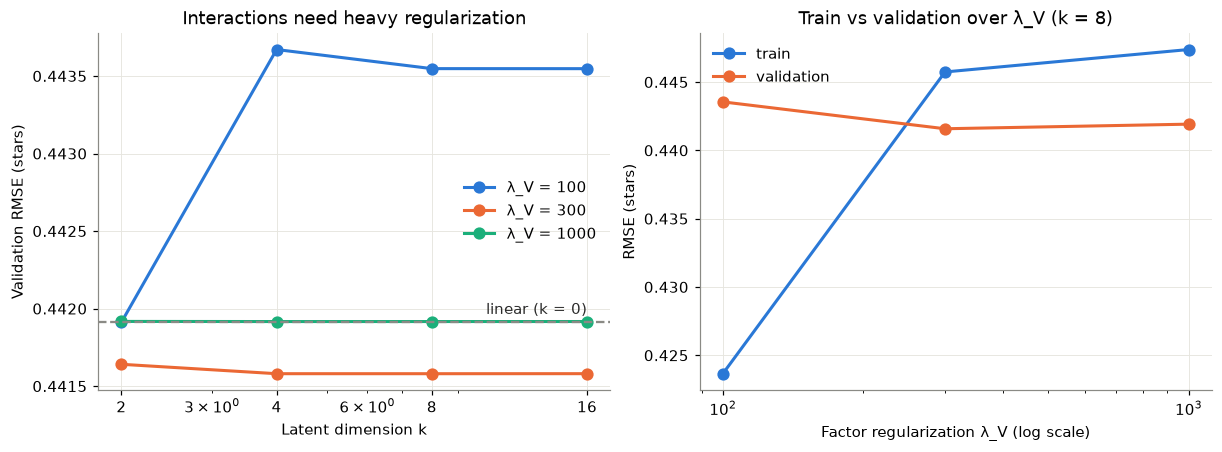

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
ax = axes[0]
for color, rv in zip(SERIES, [100., 300., 1000.]):
    s = (fm_grid[(fm_grid.reg_factors == rv) & (fm_grid.n_factors > 0)]
         .groupby('n_factors').val_rmse.min())
    ax.plot(s.index, s.values, marker='o', markersize=7, color=color, label=f'λ_V = {rv:g}')
lin = fm_grid[fm_grid.n_factors == 0].val_rmse.min()
ax.axhline(lin, color=MUTED, linestyle='--', linewidth=1.5)
ax.annotate('linear (k = 0)', (16, lin), xytext=(0, 5), textcoords='offset points', ha='right', color=INK)
ax.set(xscale='log', xticks=[2, 4, 8, 16], xticklabels=['2', '4', '8', '16'], xlabel='Latent dimension k',
       ylabel='Validation RMSE (stars)', title='Interactions need heavy regularization')
ax.legend(frameon=False)
ax = axes[1]
s = fm_grid[(fm_grid.n_factors == fm_best['n_factors']) & (fm_grid.reg_linear == fm_best['reg_linear'])]
s = s.sort_values('reg_factors')
ax.plot(s.reg_factors, s.train_rmse, marker='o', markersize=7, color=SERIES[0], label='train')
ax.plot(s.reg_factors, s.val_rmse, marker='o', markersize=7, color=SERIES[1], label='validation')
ax.set(xscale='log', xlabel='Factor regularization λ_V (log scale)', ylabel='RMSE (stars)',
       title=f"Train vs validation over λ_V (k = {fm_best['n_factors']})")
ax.legend(frameon=False)
fig.savefig(FIGURES/'D_fm_grid.png', bbox_inches='tight'); plt.show()

### Optimization and overfitting over iterations

Train and validation RMSE after every L-BFGS iteration, for the selected model and for a weakly regularized one
($\lambda_V = 10$, $k = 16$).

selected: 580 iterations, converged=True, 26.7s, final train 0.4457 / validation 0.4416, best validation 0.4416 at iteration 330


weak λ_V = 10, k = 16: 1000 iterations, converged=False, 71.3s, final train 0.2253 / validation 0.5568, best validation 0.4523 at iteration 79


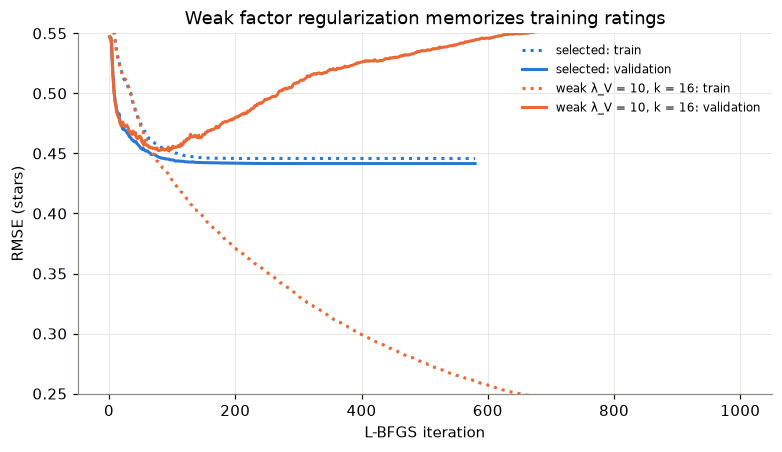

In [5]:
fm_curves = []
for label, params in [('selected', fm_best), ('weak λ_V = 10, k = 16', dict(n_factors=16, reg_linear=fm_best['reg_linear'], reg_factors=10.))]:
    m = FMRecommender(fm_fields, **params).fit(fm_train, track=fm_val)
    curve = pd.DataFrame(m.fm.curve).assign(config=label)
    fm_curves.append(curve)
    print(f"{label}: {m.fm.n_iter} iterations, converged={m.fm.converged}, {m.fit_seconds:.1f}s, "
          f"final train {curve.train_rmse.iloc[-1]:.4f} / validation {curve.val_rmse.iloc[-1]:.4f}, "
          f"best validation {curve.val_rmse.min():.4f} at iteration {curve.val_rmse.idxmin() + 1}")
fm_curves = pd.concat(fm_curves, ignore_index=True)
fm_curves.to_csv(REPORTS/'D_fm_learning_curves.csv', index=False)
fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
for color, (label, c) in zip(SERIES, fm_curves.groupby('config', sort=False)):
    ax.plot(c.iteration, c.train_rmse, color=color, linestyle=':', label=f'{label}: train')
    ax.plot(c.iteration, c.val_rmse, color=color, label=f'{label}: validation')
ax.set(ylim=(0.25, 0.55), xlabel='L-BFGS iteration', ylabel='RMSE (stars)',
       title='Weak factor regularization memorizes training ratings')
ax.legend(frameon=False, fontsize=8)
fig.savefig(FIGURES/'D_fm_learning_curves.png', bbox_inches='tight'); plt.show()

## 3.3.2 Feature ablation

Agreed order: IDs → +type → +country → +grape → +region → all (adds elaborate, winery, ABV) → +time (rating
time and vintage age). Every step is tuned on validation for both the linear model ($k = 0$, over
$\lambda_w$) and the FM (selected $k$ and $\lambda_V$, over $\lambda_w$), so each row shows the best each
representation can do.

In [6]:
def tuned_configs(name, fields):
    out = [(name, fields, dict(n_factors=0, reg_linear=rl)) for rl in [3., 5., 10.]]
    out += [(name, fields, dict(n_factors=fm_best['n_factors'], reg_linear=rl, reg_factors=fm_best['reg_factors']))
            for rl in [3., 5., 10.]]
    return out

def summarize(grid, order):
    grid = grid.assign(kind=np.where(grid.n_factors == 0, 'linear', 'fm'))
    best = grid.loc[grid.groupby(['name', 'kind']).val_rmse.idxmin()]
    table = best.pivot(index='name', columns='kind', values='val_rmse').reindex(order)
    table['fm_minus_linear'] = table.fm - table.linear
    table['features'] = best.groupby('name').features.max().reindex(order)
    return table

ablation_grid = grid_search(fm_train, fm_val, [c for name, f in ABLATION for c in tuned_configs(name, f)],
                            n_jobs=N_JOBS)
ablation_grid.to_csv(REPORTS/'D_ablation_grid.csv', index=False)
fm_ablation = summarize(ablation_grid, [n for n, _ in ABLATION])
fm_ablation['step_change_fm'] = fm_ablation.fm.diff()
fm_ablation.to_csv(REPORTS/'D_ablation.csv')
display(fm_ablation.round(4))

kind,fm,linear,fm_minus_linear,features,step_change_fm
name,,,,,
ids,0.4513,0.4513,-0.0000,11357,NaN
+type,0.4512,0.4512,-0.0000,11363,-0.0001
+country,0.4513,0.4513,0.0000,11394,0.0001
+grape,0.4514,0.4514,0.0000,11581,0.0001
+region,0.4510,0.4510,0.0000,11902,-0.0004
all,0.4506,0.4506,-0.0000,12704,-0.0003
+time,0.4416,0.4419,-0.0003,12709,-0.0091


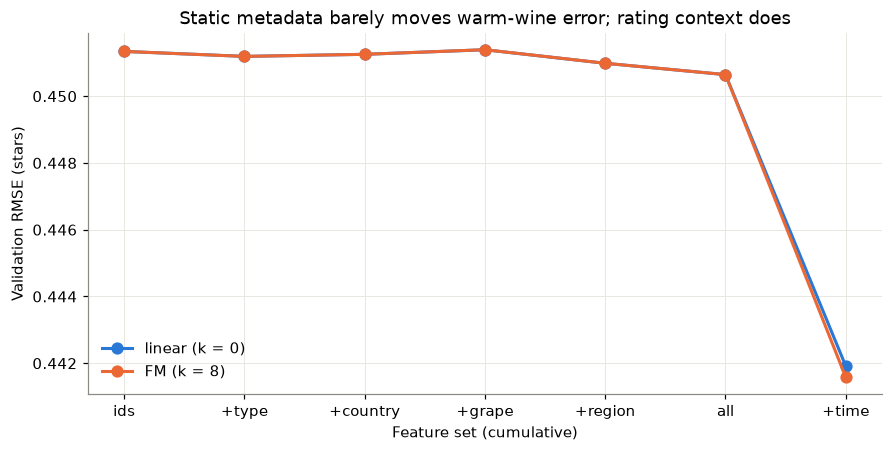

In [7]:
fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
xs = np.arange(len(fm_ablation))
ax.plot(xs, fm_ablation.linear, marker='o', markersize=7, color=SERIES[0], label='linear (k = 0)')
ax.plot(xs, fm_ablation.fm, marker='o', markersize=7, color=SERIES[1], label=f"FM (k = {fm_best['n_factors']})")
ax.set_xticks(xs, fm_ablation.index)
ax.set(xlabel='Feature set (cumulative)', ylabel='Validation RMSE (stars)',
       title='Static metadata barely moves warm-wine error; rating context does')
ax.legend(frameon=False)
fig.savefig(FIGURES/'D_ablation.png', bbox_inches='tight'); plt.show()

### Time vs vintage age

The repo's `ids_time_only` probe combines calendar time **and** vintage age and left their individual
contributions unresolved. Here they are separated, with and without static metadata.

In [8]:
context_sets = [('ids', ID_FIELDS), ('ids+Time', ID_FIELDS + ['Time']), ('ids+Age', ID_FIELDS + ['Age']),
                ('ids+Time+Age', ID_FIELDS + CONTEXT), ('all', ALL_STATIC), ('all+Time', ALL_STATIC + ['Time']),
                ('all+Age', ALL_STATIC + ['Age']), ('all+Time+Age', ALL_STATIC + CONTEXT)]
context_grid = grid_search(fm_train, fm_val, [c for n, f in context_sets for c in tuned_configs(n, f)], n_jobs=N_JOBS)
fm_context = summarize(context_grid, [n for n, _ in context_sets])
fm_context['vs_same_without_context_fm'] = fm_context.fm - fm_context.fm.loc[['ids'] * 4 + ['all'] * 4].to_numpy()
fm_context.to_csv(REPORTS/'D_time_vs_age.csv')
display(fm_context.round(4))

kind,fm,linear,fm_minus_linear,features,vs_same_without_context_fm
name,,,,,
ids,0.4513,0.4513,-0.0000,11357,0.0000
ids+Time,0.4432,0.4432,0.0000,11360,-0.0082
ids+Age,0.4506,0.4506,0.0000,11359,-0.0008
ids+Time+Age,0.4423,0.4423,0.0000,11362,-0.0090
all,0.4506,0.4506,-0.0000,12704,0.0000
all+Time,0.4417,0.4427,-0.0010,12707,-0.0089
all+Age,0.4498,0.4499,-0.0001,12706,-0.0008
all+Time+Age,0.4416,0.4419,-0.0003,12709,-0.0091


## 3.3.3 Extra features the repo left out

Added one at a time to the main feature set, then all together. **Caveat:** in X-Wines, Body and Acidity are
partly derived from user reviews (the repo's protocol excludes them for that reason), so any gain from them may
be partly leakage of review content into "metadata". Harmonize (recommended food pairings) is a catalogue field,
encoded like grapes (fractional multi-hot).

In [9]:
extra_sets = [('main', fm_fields)] + [(f'+{e}', fm_fields + [e]) for e in EXTRA] + [('+all three', fm_fields + EXTRA)]
extra_grid = grid_search(fm_train, fm_val, [c for n, f in extra_sets for c in tuned_configs(n, f)], n_jobs=N_JOBS)
fm_extra = summarize(extra_grid, [n for n, _ in extra_sets])
fm_extra['vs_main_fm'] = fm_extra.fm - fm_extra.fm.loc['main']
fm_extra.to_csv(REPORTS/'D_extra_features.csv')
display(fm_extra.round(4))

kind,fm,linear,fm_minus_linear,features,vs_main_fm
name,,,,,
main,0.4416,0.4419,-0.0003,12709,0.0000
+Body,0.4416,0.4420,-0.0003,12714,0.0000
+Acidity,0.4416,0.4419,-0.0003,12712,-0.0000
+Harmonize,0.4416,0.4420,-0.0004,12755,0.0000
+all three,0.4416,0.4420,-0.0004,12763,0.0001


## 3.3.4 Cold-start wines

The repo's `cold_item` split puts whole wines in train, validation or test, so **no test wine has a training
rating** and the wine ID carries nothing. Everything has to come from the wine's attributes, their interactions
with the user (*user × grape*, *user × country*...) and the user's own bias. We tune the same grid on the
cold-item validation wines, compare content subsets (is country or grape more informative for a new wine?), then
score test once. Repo references on this test: ridge on IDs + metadata + time 0.574, user mean 0.640.

In [10]:
cold_wines, cold_parts = load_prepared_splits(ROOT, 'cold_item')
cold_train, cold_val, cold_test = (join_metadata(cold_parts[p], cold_wines) for p in ('train', 'validation', 'test'))
assert not set(cold_test.WineID) & set(cold_train.WineID)
cold_sets = [('users only', ['UserID']), ('users+type', ['UserID', 'Type']), ('users+country', ['UserID', 'Country']),
             ('users+grape', ['UserID', 'Grapes']), ('users+region', ['UserID', 'RegionID']),
             ('all static', ALL_STATIC), ('all+time (main)', fm_fields), ('main+extras', fm_fields + EXTRA)]
cold_configs = []
for name, fields in cold_sets:
    cold_configs += [(name, fields, dict(n_factors=0, reg_linear=rl)) for rl in [3., 10., 30.]]
    cold_configs += [(name, fields, dict(n_factors=k, reg_linear=rl, reg_factors=rv))
                     for k in [fm_best['n_factors']] for rl in [3., 10., 30.] for rv in [30., 100., 300.]]
cold_grid = grid_search(cold_train, cold_val, cold_configs, n_jobs=N_JOBS)
cold_grid.to_csv(REPORTS/'D_cold_item_grid.csv', index=False)
cold_grid = cold_grid.assign(kind=np.where(cold_grid.n_factors == 0, 'linear', 'fm'))
cold_summary = (cold_grid.loc[cold_grid.groupby(['name', 'kind']).val_rmse.idxmin()]
                .pivot(index='name', columns='kind', values='val_rmse').reindex([n for n, _ in cold_sets]))
cold_summary['fm_minus_linear'] = cold_summary.fm - cold_summary.linear
display(cold_summary.round(4))

kind,fm,linear,fm_minus_linear
name,,,
users only,0.6008,0.6008,-0.0000
users+type,0.5956,0.5963,-0.0007
users+country,0.6040,0.6040,-0.0000
users+grape,0.6067,0.6067,0.0000
users+region,0.5878,0.5887,-0.0009
all static,0.5446,0.5583,-0.0137
all+time (main),0.5402,0.5480,-0.0078
main+extras,0.5475,0.5472,0.0003


In [11]:
# Selection on cold-item validation only; then one test score per selected model.
cold_choice = {}
for kind in ['fm', 'linear']:
    row = cold_grid[cold_grid.kind == kind].sort_values(['val_rmse', 'n_factors']).iloc[0]
    cold_choice[kind] = (row['name'], dict(n_factors=int(row.n_factors), reg_linear=float(row.reg_linear),
                                           reg_factors=float(row.reg_factors)))
    print(f"cold-item {kind}: {row['name']} {cold_choice[kind][1]} validation {row.val_rmse:.4f}")
cold_fields = dict(cold_sets)
cold_pred = baseline_predictions(cold_train, cold_test)
cold_fit = {}
for kind, (name, params) in cold_choice.items():
    model = FMRecommender(cold_fields[name], **params).fit(cold_train)
    cold_pred[f'{kind}: {name}'] = model.predict(cold_test); cold_fit[f'{kind}: {name}'] = model.fit_seconds
probe = FeatureProbe(['UserID', 'WineID'] + SAFE_META + ['Time', 'Age'], 10.).fit(cold_train)
cold_pred['ridge ids+metadata+time (repo)'] = probe.predict(cold_test)
fm_key = [k for k in cold_pred if k.startswith('fm:')][0]
rows = []
for name, pred in cold_pred.items():
    row = dict(model=name, **metrics(cold_test.Rating, pred), fit_seconds=cold_fit.get(name))
    if name != 'ridge ids+metadata+time (repo)':
        row.update({f'vs_ridge_{k}': v for k, v in cluster_bootstrap(
            cold_test, cold_pred['ridge ids+metadata+time (repo)'], pred).items() if k in ('delta_rmse', 'ci_low', 'ci_high')})
    rows.append(row)
fm_cold_results = pd.DataFrame(rows)
fm_cold_results.to_csv(REPORTS/'D_cold_item_test.csv', index=False)
prediction_frame(cold_test, cold_pred[fm_key]).to_csv(OUTPUTS/'D_fm_cold_item_test.csv', index=False)
display(fm_cold_results.round(4))

cold-item fm: all+time (main) {'n_factors': 8, 'reg_linear': 3.0, 'reg_factors': 100.0} validation 0.5402
cold-item linear: main+extras {'n_factors': 0, 'reg_linear': 10.0, 'reg_factors': 10.0} validation 0.5472


,model,rmse,mae,fit_seconds,vs_ridge_delta_rmse,vs_ridge_ci_low,vs_ridge_ci_high
0,global,0.6884,0.5451,NaN,0.1140,0.1086,0.1194
1,user_mean,0.6397,0.4982,NaN,0.0652,0.0609,0.0699
2,item_mean,0.6884,0.5451,NaN,0.1140,0.1086,0.1194
3,fm: all+time (main),0.5909,0.4638,35.3111,0.0165,0.0137,0.0192
4,linear: main+extras,0.5788,0.4516,3.6317,0.0043,0.0036,0.0051
5,ridge ids+metadata+time (repo),0.5744,0.4490,NaN,NaN,NaN,NaN


## 5.1 Final test evaluation (chronological)

Validation-selected models, fitted on the training partition only, scored once on the chronological test:
- **FM** (selected above), and the **linear model on the same features** (k = 0, its own best $\lambda_w$),
- **FM on IDs only** (same $k$, $\lambda$) to isolate what metadata + context add,
- references recomputed on the same rows: the repo's baselines and ridge models, and C's bias model and ALS MF.

Paired 95% user-cluster bootstrap intervals (2,000 resamples) against the repo's best ridge model and against
C's bias model; negative ΔRMSE favours the FM.

In [12]:
ids_row = ablation_grid[(ablation_grid.name == 'ids') & (ablation_grid.n_factors == fm_best['n_factors'])]
ids_params = dict(fm_best, reg_linear=float(ids_row.sort_values('val_rmse').iloc[0].reg_linear))
fm_final = {'fm': (fm_fields, fm_best), 'linear same features': (fm_fields, fm_linear_best),
            'fm ids only': (ID_FIELDS, ids_params)}
fm_models, fm_test_pred, fm_val_pred = {}, {}, {}
for name, (fields, params) in fm_final.items():
    fm_models[name] = FMRecommender(fields, **params).fit(fm_train)
    fm_test_pred[name] = fm_models[name].predict(fm_test); fm_val_pred[name] = fm_models[name].predict(fm_val)
prediction_frame(validation, fm_val_pred['fm']).to_csv(OUTPUTS/'D_fm_validation.csv', index=False)
prediction_frame(test, fm_test_pred['fm']).to_csv(OUTPUTS/'D_fm_test.csv', index=False)

reference = baseline_predictions(train, test)
ref_fit = {}
for name, fields in [('ridge ids (repo)', ['UserID', 'WineID']),
                     ('ridge ids+metadata+time (repo)', ['UserID', 'WineID'] + SAFE_META + ['Time', 'Age'])]:
    start = time.perf_counter(); probe = FeatureProbe(fields, 10.).fit(fm_train)
    ref_fit[name] = time.perf_counter() - start; reference[name] = probe.predict(fm_test)
ridge_probe = probe
start = time.perf_counter(); bias_model = BiasBaseline(5, 2).fit(train); ref_fit['bias (C)'] = time.perf_counter() - start
reference['bias (C)'] = bias_model.predict(test)
start = time.perf_counter(); als_model = ALSMF(8, 11., reg_user_bias=5, reg_item_bias=2, n_iter=10).fit(train)
ref_fit['als mf (C)'] = time.perf_counter() - start
reference['als mf (C)'] = als_model.predict(test)

settings = {'fm': f"k={fm_best['n_factors']}, λ_w={fm_best['reg_linear']:g}, λ_V={fm_best['reg_factors']:g}",
            'linear same features': f"k=0, λ_w={fm_linear_best['reg_linear']:g}",
            'fm ids only': f"k={ids_params['n_factors']}, λ_w={ids_params['reg_linear']:g}, λ_V={ids_params['reg_factors']:g}",
            'bias (C)': 'reg_user=5, reg_item=2', 'als mf (C)': 'k=8, λ=11'}
rows = []
for name, pred in {**reference, **fm_test_pred}.items():
    row = dict(model=name, settings=settings.get(name, 'repo reference'), **metrics(test.Rating, pred),
               fit_seconds=fm_models[name].fit_seconds if name in fm_models else ref_fit.get(name))
    if name in fm_test_pred:
        for ref in ['ridge ids+metadata+time (repo)', 'bias (C)']:
            b = cluster_bootstrap(test, reference[ref], pred)
            tag = 'ridge' if ref.startswith('ridge') else 'bias'
            row.update({f'vs_{tag}_delta': b['delta_rmse'], f'vs_{tag}_ci_low': b['ci_low'], f'vs_{tag}_ci_high': b['ci_high']})
    rows.append(row)
fm_results = pd.DataFrame(rows)
fm_results.to_csv(REPORTS/'D_test_metrics.csv', index=False)
display(fm_results.round(4))

,model,settings,rmse,mae,fit_seconds,vs_ridge_delta,vs_ridge_ci_low,vs_ridge_ci_high,vs_bias_delta,vs_bias_ci_low,vs_bias_ci_high
0,global,repo reference,0.6123,0.4932,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,user_mean,repo reference,0.5878,0.4649,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,item_mean,repo reference,0.4785,0.3682,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ridge ids (repo),repo reference,0.4493,0.3401,0.4706,NaN,NaN,NaN,NaN,NaN,NaN
4,ridge ids+metadata+time (repo),repo reference,0.4332,0.3177,1.4279,NaN,NaN,NaN,NaN,NaN,NaN
5,bias (C),"reg_user=5, reg_item=2",0.4457,0.3356,0.0167,NaN,NaN,NaN,NaN,NaN,NaN
6,als mf (C),"k=8, λ=11",0.4460,0.3358,0.9610,NaN,NaN,NaN,NaN,NaN,NaN
7,fm,"k=8, λ_w=5, λ_V=300",0.4315,0.3174,19.4884,-0.0016,-0.0030,-0.0002,-0.0142,-0.0163,-0.0120
8,linear same features,"k=0, λ_w=5",0.4315,0.3165,2.5030,-0.0017,-0.0028,-0.0005,-0.0142,-0.0164,-0.0121
9,fm ids only,"k=8, λ_w=5, λ_V=300",0.4469,0.3370,1.4069,0.0137,0.0111,0.0164,0.0012,0.0008,0.0015


In [13]:
# The team scorer must agree with these numbers (same check C runs).
out = subprocess.run([sys.executable, 'scripts/evaluate_predictions.py', 'outputs/D_fm_test.csv', '--partition', 'test'],
                     cwd=ROOT, capture_output=True, text=True, check=True)
check = json.loads(out.stdout)
assert abs(check['rmse'] - fm_results.set_index('model').loc['fm', 'rmse']) < 1e-12
print('Shared scorer agrees:', {k: round(v, 4) if isinstance(v, float) else v for k, v in check.items()})
out = subprocess.run([sys.executable, 'scripts/evaluate_predictions.py', 'outputs/D_fm_cold_item_test.csv',
                      '--partition', 'test', '--protocol', 'cold_item'], cwd=ROOT, capture_output=True, text=True, check=True)
print('Cold-item FM, shared scorer:', json.loads(out.stdout))

Shared scorer agrees: {'rows': 15000, 'clipped': 0, 'rmse': 0.4315, 'mae': 0.3174}


Cold-item FM, shared scorer: {'rows': 14536, 'clipped': 0, 'rmse': 0.5908995910952722, 'mae': 0.46378014929809985}


### Combined comparison table (A + C + D)

C's validation-selected models come from `reports/C_test_metrics.csv` (same test rows, same scorer); the
repo's ridge and baselines from A. Sorted by test RMSE.

In [14]:
combined = [fm_results.assign(owner=np.where(fm_results.model.isin(fm_test_pred), 'D',
                                             np.where(fm_results.model.str.contains(r'\(C\)'), 'C (refit here)', 'A (repo)')))]
c_path = REPORTS/'C_test_metrics.csv'
if c_path.exists():
    c = pd.read_csv(c_path)
    c = c[~c.model.isin(['global', 'user_mean', 'item_mean', 'ridge_ids (repo)', 'bias', 'als_mf'])]
    combined.append(c[['model', 'settings', 'rmse', 'mae', 'fit_seconds']].assign(owner='C'))
final_table = (pd.concat(combined, ignore_index=True)[['owner', 'model', 'settings', 'rmse', 'mae', 'fit_seconds']]
               .sort_values('rmse').reset_index(drop=True))
final_table.to_csv(REPORTS/'D_final_comparison.csv', index=False)
display(final_table.round(4))

,owner,model,settings,rmse,mae,fit_seconds
0,D,linear same features,"k=0, λ_w=5",0.4315,0.3165,2.5030
1,D,fm,"k=8, λ_w=5, λ_V=300",0.4315,0.3174,19.4884
2,A (repo),ridge ids+metadata+time (repo),repo reference,0.4332,0.3177,1.4279
3,C,item_cf,"cosine, k=10, damping=1",0.4446,0.3342,0.8149
4,C,surprise_svd,"k=4, reg=0.02, epochs=20",0.4457,0.3350,1.2132
5,C,surprise_svdpp,"k=4, reg=0.02, epochs=20",0.4457,0.3351,2.5496
6,C (refit here),bias (C),"reg_user=5, reg_item=2",0.4457,0.3356,0.0167
7,C (refit here),als mf (C),"k=8, λ=11",0.4460,0.3358,0.9610
8,D,fm ids only,"k=8, λ_w=5, λ_V=300",0.4469,0.3370,1.4069
9,A (repo),ridge ids (repo),repo reference,0.4493,0.3401,0.4706


## 5.1b Who is easier to predict, and does metadata help warm wines?

Error slices with the repo's `error_slices()` (training-count bins per user and per wine, warm / new-user /
new-wine regimes), the same breakdown C uses. "fm ids only" vs "fm" isolates what metadata + context add.

In [15]:
slice_preds = {'fm': fm_test_pred['fm'], 'fm ids only': fm_test_pred['fm ids only'],
               'ridge ids+metadata+time (repo)': reference['ridge ids+metadata+time (repo)'],
               'bias (C)': reference['bias (C)'], 'als mf (C)': reference['als mf (C)']}
fm_slices = pd.concat([error_slices(train, test, p, name) for name, p in slice_preds.items()], ignore_index=True)
fm_slices.to_csv(REPORTS/'D_error_slices.csv', index=False)
view = fm_slices.pivot_table(index=['slice', 'group'], columns='model', values='rmse', sort=False)
view.insert(0, 'n', fm_slices.groupby(['slice', 'group'], sort=False).n.first())
view['fm − ids only'] = view['fm'] - view['fm ids only']
display(view.round(4))

model                         n      fm  fm ids only  \
slice          group                                   
regime         new_both       2  0.3917       0.2605   
               new_item      14  0.7579       0.6617   
               new_user     981  0.5072       0.5276   
               warm_both  14003  0.4253       0.4404   
UserID_history 0            983  0.5070       0.5272   
               1-5         3487  0.4384       0.4532   
               6-20        8898  0.4268       0.4417   
               21-100      1632  0.3913       0.4070   
WineID_history 0             16  0.7224       0.6258   
               1-5          112  0.4292       0.4624   
               6-20         493  0.4801       0.4997   
               21-100      2128  0.4226       0.4378   
               101+       12251  0.4305       0.4458   

model                     ridge ids+metadata+time (repo)  bias (C)  \
slice          group                                                 
regime         new_both                           0.2641    0.2524   
               new_item                           0.7381    0.6802   
               new_user                           0.5061    0.5251   
               warm_both                          0.4272    0.4394   
UserID_history 0                                  0.5057    0.5247   
               1-5                                0.4426    0.4523   
               6-20                               0.4285    0.4408   
               21-100                             0.3884    0.4046   
WineID_history 0                                  0.6967    0.6425   
               1-5                                0.4241    0.4445   
               6-20                               0.4761    0.4880   
               21-100                             0.4231    0.4368   
               101+                               0.4327    0.4452   

model                     als mf (C)  fm − ids only  
slice          group                                 
regime         new_both       0.2524         0.1312  
               new_item       0.6777         0.0962  
               new_user       0.5254        -0.0204  
               warm_both      0.4396        -0.0152  
UserID_history 0              0.5250        -0.0202  
               1-5            0.4533        -0.0148  
               6-20           0.4409        -0.0149  
               21-100         0.4041        -0.0156  
WineID_history 0              0.6402         0.0966  
               1-5            0.4447        -0.0332  
               6-20           0.4874        -0.0196  
               21-100         0.4368        -0.0152  
               101+           0.4455        -0.0153

## 5.3 Interpreting the weights

Linear weights $w_j$ of the selected FM (stars relative to the other levels, after user and wine IDs) and of the
repo's ridge model on IDs + metadata + time. Because the wine ID is in the model, a metadata weight only captures
what is shared by wines *beyond* their own IDs, so these are shrunk towards zero for well-rated wines. Weights
for categories with fewer than 5 training wines are dropped as too noisy.

In [16]:
train_wines = fm_train.drop_duplicates('WineID')
support = {}
for field, col in [('Type', 'Type'), ('Country', 'Country'), ('RegionID', 'RegionID'), ('Elaborate', 'Elaborate')]:
    support.update({f'{field}={v}': n for v, n in train_wines[col].value_counts().items()})
support.update({f'Grapes={g}': n for g, n in train_wines.GrapeList.explode().value_counts().items()})
fm_w = fm_models['fm'].weights()
fm_w['train_wines'] = fm_w.feature.map(support)
ridge_w = pd.Series(ridge_probe.model.coef_, index=ridge_probe.vectorizer.feature_names_)
ridge_w.index = ridge_w.index.str.replace('grape=', 'Grapes=')
fm_w['ridge_weight'] = fm_w.feature.map(ridge_w)
region_names = wines.drop_duplicates('RegionID').set_index('RegionID').RegionName
fm_w['label'] = fm_w.feature.str.split('=', n=1).str[1]
is_region = fm_w.field.eq('RegionID')
fm_w.loc[is_region, 'label'] = fm_w.loc[is_region, 'label'].astype(float).map(region_names)
meta_w = fm_w[fm_w.field.isin(['Type', 'Country', 'Grapes', 'RegionID', 'Elaborate', 'ABV', 'Time', 'Age'])].copy()
meta_w.to_csv(REPORTS/'D_feature_weights.csv', index=False)
for field in ['Type', 'Country', 'Grapes']:
    t = meta_w[(meta_w.field == field) & (meta_w.train_wines >= 5)].sort_values('weight')
    print(f'\n{field}: lowest and highest FM weights (ridge weight alongside)')
    shown = t if len(t) <= 10 else pd.concat([t.head(5), t.tail(5)])
    display(shown[['label', 'train_wines', 'weight', 'ridge_weight']].round(3))
print('\nContext and ABV weights:')
display(meta_w[meta_w.field.isin(['ABV', 'Time', 'Age'])][['feature', 'weight', 'ridge_weight']].round(3))
print('Correlation of FM and ridge weights over metadata features:',
      round(meta_w[['weight', 'ridge_weight']].corr().iloc[0, 1], 3))


Type: lowest and highest FM weights (ridge weight alongside)


,label,train_wines,weight,ridge_weight
11362,Rosé,83.0,-0.215,-0.314
11360,White,230.0,-0.086,-0.196
11357,Red,506.0,-0.026,-0.133
11358,Dessert,58.0,0.071,-0.037
11359,Sparkling,98.0,0.077,-0.031
11361,Dessert/Port,25.0,0.172,0.068



Country: lowest and highest FM weights (ridge weight alongside)


,label,train_wines,weight,ridge_weight
11399,Russia,7.0,-0.196,-0.208
11386,Brazil,48.0,-0.171,-0.179
11388,Chile,69.0,-0.159,-0.184
11396,Uruguay,8.0,-0.123,-0.129
11395,Mexico,7.0,-0.076,-0.094
11390,Germany,53.0,0.133,0.108
11387,Australia,48.0,0.149,0.113
11381,New Zealand,33.0,0.181,0.132
11376,France,179.0,0.211,0.156
11379,United States,113.0,0.258,0.213



Grapes: lowest and highest FM weights (ridge weight alongside)


,label,train_wines,weight,ridge_weight
12567,Gamay Noir,10.0,-0.182,-0.187
12538,Touriga Franca,32.0,-0.125,-0.106
12602,Tannat,9.0,-0.116,-0.128
12515,Merlot,100.0,-0.107,-0.123
12592,Trebbiano,5.0,-0.106,-0.102
12597,Assyrtiko,5.0,0.128,0.092
12577,Furmint,5.0,0.183,0.172
12591,Malvasia,7.0,0.194,0.189
12517,Cabernet Franc,60.0,0.238,0.219
12518,Petit Verdot,27.0,0.289,0.257



Context and ABV weights:


,feature,weight,ridge_weight
12702,ABV_z,0.060,0.081
12703,ABV_missing,0.000,0.000
12704,month_sin,-0.012,-0.011
12705,month_cos,0.005,-0.002
12706,year_centered,0.205,0.161
12707,age_decades,0.037,0.044
12708,age_missing,-0.115,-0.125


Correlation of FM and ridge weights over metadata features: 0.987


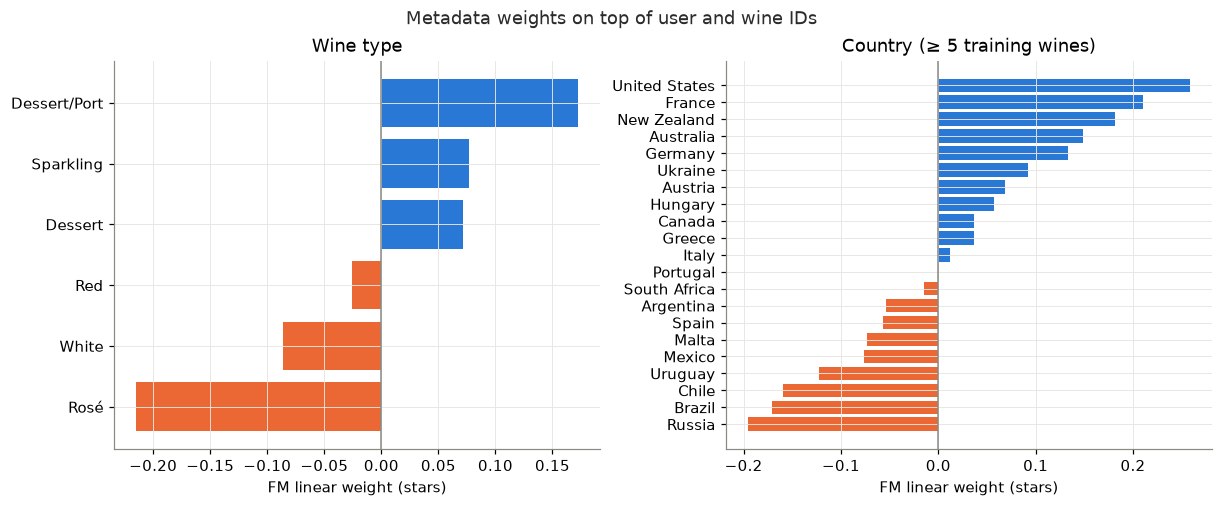

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout='constrained')
t = meta_w[meta_w.field == 'Type'].sort_values('weight')
axes[0].barh(t.label, t.weight, color=[SERIES[1] if w < 0 else SERIES[0] for w in t.weight])
axes[0].axvline(0, color=MUTED, linewidth=1)
axes[0].set(xlabel='FM linear weight (stars)', title='Wine type')
g = meta_w[(meta_w.field == 'Country') & (meta_w.train_wines >= 5)].sort_values('weight')
axes[1].barh(g.label, g.weight, color=[SERIES[1] if w < 0 else SERIES[0] for w in g.weight])
axes[1].axvline(0, color=MUTED, linewidth=1)
axes[1].set(xlabel='FM linear weight (stars)', title='Country (≥ 5 training wines)')
fig.suptitle('Metadata weights on top of user and wine IDs', color=INK)
fig.savefig(FIGURES/'D_feature_weights.png', bbox_inches='tight'); plt.show()

### How personal are the learned interactions?

For each wine type (and the top countries/grapes), the spread across users of the FM's pairwise term
$\langle v_u, v_{\text{type}}\rangle$: how much the model lets one user's preference for that type differ from
another's. Compare with the type's own linear weight.

In [18]:
spread = []
for field in ['Type', 'Country', 'Grapes']:
    s = interaction_spread(fm_models['fm'], 'UserID', field).assign(field=field)
    spread.append(s.head(8))
spread = pd.concat(spread, ignore_index=True)
spread['linear_weight'] = spread.feature.map(fm_w.set_index('feature').weight)
spread.to_csv(REPORTS/'D_user_interaction_spread.csv', index=False)
display(spread.round(4))
# Interactions that do not involve the user: rating year x wine type (context x metadata).
f = fm_models['fm'].factors()
year_type = pd.Series(f.loc[[c for c in f.index if c.startswith('Type=')]].to_numpy() @ f.loc['year_centered'].to_numpy(),
                      index=[c for c in f.index if c.startswith('Type=')], name='<v_year, v_type>')
print('Rating-year x type interaction (stars per 5 years, on top of the year weight):')
display(year_type.sort_values().round(4).to_frame())
norms = fm_w.groupby('field').factor_norm.mean().sort_values(ascending=False)
print('Mean factor norm |v_j| by field:'); display(norms.round(4).to_frame())

,feature,std_over_users,mean_abs,field,linear_weight
0,Type=Rosé,0.0000,0.0000,Type,-0.2149
1,Type=Dessert/Port,0.0000,0.0000,Type,0.1724
2,Type=Sparkling,0.0000,0.0000,Type,0.0769
3,Type=White,0.0000,0.0000,Type,-0.0865
4,Type=Dessert,0.0000,0.0000,Type,0.0713
5,Type=Red,0.0000,0.0000,Type,-0.0255
6,Country=Brazil,0.0001,0.0001,Country,-0.1706
7,Country=Germany,0.0001,0.0000,Country,0.1334
8,Country=Spain,0.0001,0.0000,Country,-0.0571
9,Country=Argentina,0.0000,0.0000,Country,-0.0538


Rating-year x type interaction (stars per 5 years, on top of the year weight):

,"<v_year, v_type>"
Type=White,-0.0071
Type=Sparkling,-0.0065
Type=Dessert/Port,-0.0055
Type=Red,-0.0006
Type=Dessert,0.0030
Type=Rosé,0.0111


Mean factor norm |v_j| by field:


,factor_norm
field,
Age,0.1639
Time,0.1621
ABV,0.0619
Type,0.0233
Country,0.0172
Elaborate,0.0102
RegionID,0.0050
Grapes,0.0043
WineryID,0.0034


## 5.4 Top-K ranking: FM vs C's matrix factorization

Ranking protocol (fixed before looking at results, as the repo's protocol asks):
- **Eligible users:** seen in training, with at least one *relevant* test wine (rating ≥ 4) that is not already
  in their training history.
- **Candidates:** every catalogue wine except the user's training wines; the same users and candidates for every
  model.
- **Metrics:** Precision@10, Recall@10, MRR (reciprocal rank of the first relevant wine) and AUC (relevant vs every
  other candidate), averaged over users.
- **Models:** the FM on IDs + static metadata (time and vintage age are not defined for a wine the user has
  never rated, so the context features are left out for ranking; same $k$, $\lambda$ as selected), C's ALS MF
  (k = 8, λ = 11), C's bias model, and training popularity.

**Caveat:** a candidate the user did not rate is counted as not relevant, although the user may simply never have
seen it; ratings are not exposures, and historical availability of the wines is unknown. Absolute values are
therefore low and only the comparison between models is meaningful.

In [19]:
wine_ids = np.sort(wines.WineID.to_numpy())
wine_meta = wines.set_index('WineID').loc[wine_ids].reset_index()
topk_users, topk_exclude, topk_relevant = topk_setup(train, test, wine_ids)
print(f'{len(topk_users):,} eligible users, {len(wine_ids):,} catalogue wines, '
      f'{topk_relevant.sum(1).mean():.2f} relevant test wines per user on average')
static_model = FMRecommender(ALL_STATIC, **fm_best).fit(fm_train)
popularity = train.WineID.value_counts().reindex(wine_ids).fillna(0).to_numpy()
score_sets = {
    'fm (IDs + static metadata)': fm_score_matrix(static_model, topk_users, wine_meta),
    'als mf (C)': frame_score_matrix(als_model.raw, topk_users, wine_ids),
    'bias (C)': frame_score_matrix(bias_model.raw, topk_users, wine_ids),
    'popularity': np.tile(popularity, (len(topk_users), 1)),
}
# Check the fast FM scorer against ordinary row-by-row prediction on a sample of pairs.
rng = np.random.default_rng(SEED)
r, c = rng.integers(0, len(topk_users), 500), rng.integers(0, len(wine_ids), 500)
sample = join_metadata(pd.DataFrame({'UserID': topk_users[r], 'WineID': wine_ids[c]}), wines)
assert np.allclose(static_model.raw(sample), score_sets['fm (IDs + static metadata)'][r, c])
topk_rows, topk_lists = [], {}
for name, scores in score_sets.items():
    result, topk_lists[name] = topk_metrics(scores, topk_exclude, topk_relevant, k=10)
    topk_rows.append(dict(model=name, **result))
fm_topk = pd.DataFrame(topk_rows)
fm_topk.to_csv(REPORTS/'D_topk.csv', index=False)
display(fm_topk.round(4))

4,684 eligible users, 1,007 catalogue wines, 2.09 relevant test wines per user on average


,model,users,precision_at_k,recall_at_k,mrr,auc
0,fm (IDs + static metadata),4684,0.0079,0.0345,0.0271,0.7138
1,als mf (C),4684,0.0082,0.0364,0.0407,0.7130
2,bias (C),4684,0.0080,0.0349,0.0408,0.7126
3,popularity,4684,0.0183,0.0913,0.0704,0.8495


### Diversity of the top-10 lists

Are the lists dominated by reds or by one country? Shares are over all recommended slots; *coverage* is the
fraction of the catalogue recommended to anyone; *Gini* is the concentration of recommendation counts over
wines (0 = every wine equally often, 1 = one wine for everybody). The candidate catalogue and the training
ratings are shown for calibration.

In [20]:
div_rows = [dict(model=name, **diversity(lists, wine_meta)) for name, lists in topk_lists.items()]
train_meta = join_metadata(train, wines)
div_rows.append(dict(model='catalogue (all wines)', red_share=float(wine_meta.Type.eq('Red').mean()),
                     top_country=wine_meta.Country.value_counts().index[0],
                     top_country_share=float(wine_meta.Country.value_counts(normalize=True).iloc[0])))
div_rows.append(dict(model='training ratings', red_share=float(train_meta.Type.eq('Red').mean()),
                     top_country=train_meta.Country.value_counts().index[0],
                     top_country_share=float(train_meta.Country.value_counts(normalize=True).iloc[0])))
fm_diversity = pd.DataFrame(div_rows)
fm_diversity.to_csv(REPORTS/'D_diversity.csv', index=False)
display(fm_diversity.round(3))

,model,red_share,top_country,top_country_share,countries_per_list,types_per_list,catalogue_coverage,gini
0,fm (IDs + static metadata),0.702,United States,0.416,3.957,3.978,0.016,0.990
1,als mf (C),0.702,United States,0.428,3.961,3.978,0.021,0.990
2,bias (C),0.702,United States,0.415,3.958,3.978,0.016,0.990
3,popularity,0.980,Argentina,0.368,6.232,1.197,0.018,0.989
4,catalogue (all wines),0.502,France,0.178,NaN,NaN,NaN,NaN
5,training ratings,0.664,France,0.263,NaN,NaN,NaN,NaN


## 3.5 Noise and missing data in D's features

In [21]:
tw = fm_train.drop_duplicates('WineID')
nv = train.Vintage.eq('N.V.')
age = (fm_train.Date.dt.year - pd.to_numeric(fm_train.Vintage, errors='coerce')).astype(float)
grape_counts = tw.GrapeList.map(len)
region_support = tw.RegionID.value_counts(); grape_support = tw.GrapeList.explode().value_counts()
issues = pd.Series({
    'Slim ratings with Vintage N.V.': int(pd.concat(parts.values()).Vintage.eq('N.V.').sum()),
    'train ratings with Vintage N.V.': int(nv.sum()),
    'train ratings with missing/invalid age (N.V., future, >100y)': int((~age.between(0, 100).fillna(False).astype(bool)).sum()),
    'mean rating, N.V. train rows': float(train.Rating[nv].mean()),
    'mean rating, vintage train rows': float(train.Rating[~nv].mean()),
    'train wines that are blends (>1 grape)': int((grape_counts > 1).sum()),
    'train wines total': len(tw),
    'max grapes in one wine': int(grape_counts.max()),
    'train wines with missing ABV': int(tw.ABV.isna().sum()),
    'regions in train': len(region_support),
    'regions with < 3 training wines': int((region_support < 3).sum()),
    'grapes with < 3 training wines': int((grape_support < 3).sum()),
    'grapes in train': len(grape_support),
})
issues.to_frame('value').to_csv(REPORTS/'D_data_issues.csv')
display(issues.to_frame('value'))
w = meta_w.dropna(subset=['train_wines'])
print('Mean |FM weight| by training-wine support:')
display(w.groupby(pd.cut(w.train_wines, [0, 2, 5, 20, 1000]), observed=True).weight
        .agg(n='size', mean_abs=lambda s: s.abs().mean()).round(4))

,value
Slim ratings with Vintage N.V.,9643.000000
train ratings with Vintage N.V.,7381.000000
"train ratings with missing/invalid age (N.V., future, >100y)",7381.000000
"mean rating, N.V. train rows",3.675789
"mean rating, vintage train rows",3.791478
train wines that are blends (>1 grape),288.000000
train wines total,1000.000000
max grapes in one wine,9.000000
train wines with missing ABV,0.000000
regions in train,321.000000


Mean |FM weight| by training-wine support:


,n,mean_abs
train_wines,,
"(0, 2]",336,0.0738
"(2, 5]",101,0.0941
"(5, 20]",75,0.0902
"(20, 1000]",46,0.1080


## Findings (Person D)

See `reports/D_findings.md` for the written conclusions with the numbers from this run.